# Matplotlib grafer – load test

Responstid for hver request ved 1, 10, 50 og 1000 samtidige requests (kørslen med 2000 requests pr. niveau),
holdt op mod gennemsnittet og 95. percentil. Data er de `loadtest-c*.csv`, som `Improved/loadtest.js` skriver i denne mappe.

Kør notebooken fra `Improved/results/`. Kræver `pip install pandas matplotlib jupyter`.
Graferne gemmes også som PNG i `figures/`.

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RESULTS_DIR = Path.cwd()          # The notebook lives in Improved/results
FIG_DIR = RESULTS_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True)

# Recessive axes and grid, thin marks
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
    "font.size": 10,
    "axes.edgecolor": "#c8c8c8",
    "axes.labelcolor": "#191919",
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e8e8e8",
    "grid.linewidth": 0.8,
    "xtick.color": "#666666",
    "ytick.color": "#666666",
    "text.color": "#191919",
    "lines.linewidth": 2,
    "legend.frameon": False,
})

# Fixed categorical order: each concurrency level keeps its color in every chart
PALETTE = ["#257de0", "#f47230", "#00b894", "#f2a600", "#ee7fac", "#008a17", "#6a4ce2", "#ec4647"]
TEXT_PRIMARY, TEXT_SECONDARY = "#191919", "#666666"

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")


def percentile(sorted_times, p):
    # Nearest-rank percentile, as in loadtest.js
    if len(sorted_times) == 0:
        return np.nan
    rank = int(np.ceil(p / 100 * len(sorted_times)))
    return sorted_times[max(0, rank - 1)]

## Indlæs data

In [2]:
# Filename pattern written by loadtest.js: loadtest-c<concurrency>-<ISO time with : and . replaced by ->.csv
PATTERN = re.compile(r"loadtest-c(\d+)-(\d{4}-\d{2}-\d{2})T(\d{2})-(\d{2})-(\d{2})-(\d{3})Z\.csv")

frames = []
for path in sorted(RESULTS_DIR.glob("loadtest-c*.csv")):
    m = PATTERN.fullmatch(path.name)
    if not m:
        print("Skipping", path.name)
        continue
    conc = m.group(1)
    df = pd.read_csv(path, parse_dates=["sent_at"], keep_default_na=False)
    df["ok"] = df["ok"].astype(str).str.lower() == "true"
    df["concurrency"] = int(conc)
    df["file"] = path.name
    df["run"] = f"{len(df)} req"   # Runs are told apart by --requests
    frames.append(df)

data = pd.concat(frames, ignore_index=True)

LEVELS = sorted(int(c) for c in data["concurrency"].unique())
COLOR = {c: PALETTE[i] for i, c in enumerate(LEVELS)}

print(f"{len(frames)} filer, {len(data)} requests")
print("Concurrency:", LEVELS, "| Kørsler:", sorted(data["run"].unique()))
data.groupby(["run", "concurrency"]).agg(requests=("index", "size"), fil=("file", "first"))

7 filer, 11000 requests
Concurrency: [1, 10, 50, 1000] | Kørsler: ['1000 req', '2000 req']


requests                                          fil
run      concurrency                                                       
1000 req 1                1000     loadtest-c1-2026-11-20T10-53-14-908Z.csv
         10               1000    loadtest-c10-2026-11-20T10-53-15-572Z.csv
         50               1000    loadtest-c50-2026-11-20T10-53-16-206Z.csv
2000 req 1                2000     loadtest-c1-2026-11-20T10-56-07-208Z.csv
         10               2000    loadtest-c10-2026-11-20T10-56-08-440Z.csv
         50               2000    loadtest-c50-2026-11-20T10-56-09-682Z.csv
         1000             2000  loadtest-c1000-2026-11-20T10-56-12-340Z.csv

## Hver request vs. gennemsnit (c1, c10, c50, c1000 – 2000 req)

Hver prik er én request ved 1, 10, 50 og 1000 samtidige requests. Prikkerne er spredt lidt sidelæns, så de ikke ligger oven i hinanden; den sorte streg er gennemsnittet (average response time).

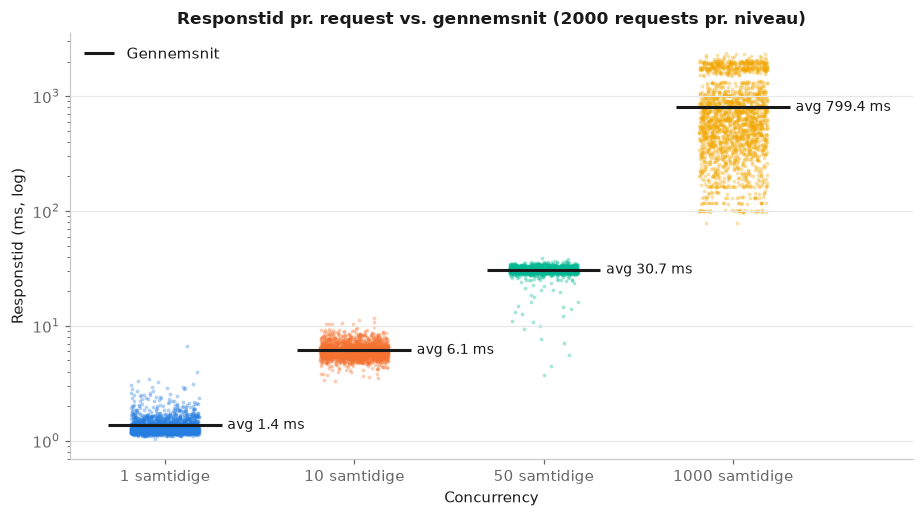

In [3]:
SCATTER_LEVELS = [1, 10, 50, 1000]
SCATTER_RUN = "2000 req"
rng = np.random.default_rng(0)  # Fixed seed so the jitter looks the same every run

subset = data[(data["run"] == SCATTER_RUN) & data["concurrency"].isin(SCATTER_LEVELS) & data["ok"]]

fig, ax = plt.subplots(figsize=(8.5, 4.8))
for pos, c in enumerate(SCATTER_LEVELS):
    times = subset.loc[subset["concurrency"] == c, "response_ms"]
    jitter = rng.uniform(-0.18, 0.18, len(times))
    ax.scatter(pos + jitter, times, s=6, alpha=0.35, color=COLOR[c], linewidths=0)
    mean = times.mean()
    ax.hlines(mean, pos - 0.3, pos + 0.3, color=TEXT_PRIMARY, linewidth=2,
              label="Gennemsnit" if pos == 0 else None)
    ax.text(pos + 0.33, mean, f"avg {mean:.1f} ms", va="center", fontsize=9, color=TEXT_PRIMARY)

ax.set_yscale("log")
ax.set_xticks(range(len(SCATTER_LEVELS)), [f"{c} samtidige" for c in SCATTER_LEVELS])
ax.set_xlim(-0.5, len(SCATTER_LEVELS) - 0.5 + 0.45)
ax.grid(axis="x", visible=False)
ax.set_xlabel("Concurrency")
ax.set_ylabel("Responstid (ms, log)")
ax.set_title("Responstid pr. request vs. gennemsnit (2000 requests pr. niveau)")
ax.legend(loc="upper left")
fig.tight_layout()
save(fig, "scatter_vs_gennemsnit")
plt.show()

## Hver request vs. 95. percentil (c1, c10, c50, c1000 – 2000 req)

Samme graf som ovenfor, men den sorte streg er p95: 95 % af requests blev besvaret på eller under denne tid.

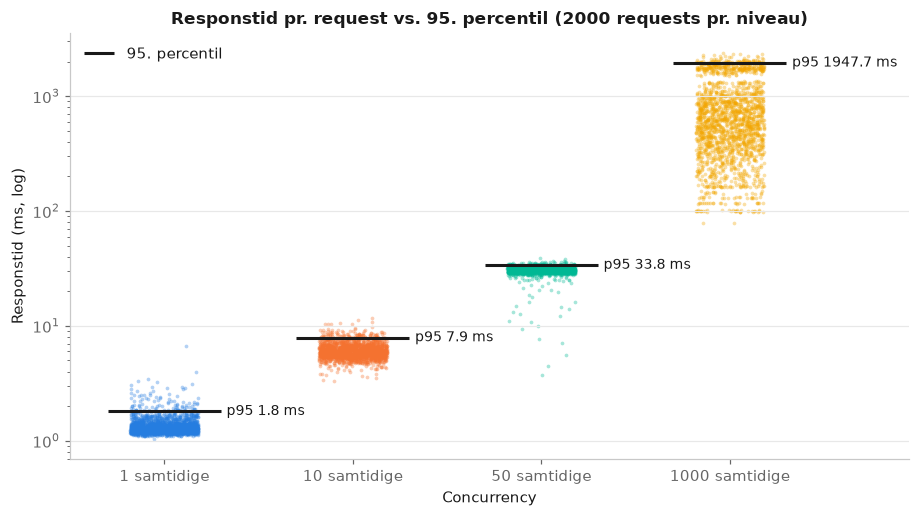

In [4]:
rng = np.random.default_rng(0)  # Same jitter as the average plot above

fig, ax = plt.subplots(figsize=(8.5, 4.8))
for pos, c in enumerate(SCATTER_LEVELS):
    times = subset.loc[subset["concurrency"] == c, "response_ms"]
    jitter = rng.uniform(-0.18, 0.18, len(times))
    ax.scatter(pos + jitter, times, s=6, alpha=0.35, color=COLOR[c], linewidths=0)
    p95 = percentile(np.sort(times.to_numpy()), 95)  # Nearest-rank, same as loadtest.js
    ax.hlines(p95, pos - 0.3, pos + 0.3, color=TEXT_PRIMARY, linewidth=2,
              label="95. percentil" if pos == 0 else None)
    ax.text(pos + 0.33, p95, f"p95 {p95:.1f} ms", va="center", fontsize=9, color=TEXT_PRIMARY)

ax.set_yscale("log")
ax.set_xticks(range(len(SCATTER_LEVELS)), [f"{c} samtidige" for c in SCATTER_LEVELS])
ax.set_xlim(-0.5, len(SCATTER_LEVELS) - 0.5 + 0.45)
ax.grid(axis="x", visible=False)
ax.set_xlabel("Concurrency")
ax.set_ylabel("Responstid (ms, log)")
ax.set_title("Responstid pr. request vs. 95. percentil (2000 requests pr. niveau)")
ax.legend(loc="upper left")
fig.tight_layout()
save(fig, "scatter_vs_p95")
plt.show()